# 04 — Avaliação dos Modelos e Interpretação dos Resultados
### Tech Challenge — Fase 2 | Pós Tech Data Analytics (14DTAT) | Luis Guilherme Betarelli Lopes (RM374939)

Este notebook avalia os três modelos treinados em `03_modelagem.ipynb` no
conjunto de teste, usando métricas além de acurácia, e interpreta os
resultados em termos de negócio.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

## 1. Carregando dados de teste e modelos treinados

In [2]:
test = pd.read_csv("../data/processed/test.csv")
X_test = test.drop(columns=["quality_label"])
y_test = test["quality_label"]

modelos = {
    "KNN": joblib.load("../data/processed/models/knn.pkl"),
    "Árvore de Decisão": joblib.load("../data/processed/models/arvore_de_decisao.pkl"),
    "Random Forest": joblib.load("../data/processed/models/random_forest.pkl"),
}
print("Modelos carregados:", list(modelos.keys()))

Modelos carregados: ['KNN', 'Árvore de Decisão', 'Random Forest']


## 2. Por que olhar além da acurácia

A EDA (notebook 01) mostrou que a base é desbalanceada: ~14% das amostras são
de Alta Qualidade. Um modelo que sempre prevê "Baixa/Média Qualidade" já
acertaria ~86% das vezes sem aprender nada útil. Por isso, priorizamos aqui
`precision`, `recall`, `F1-score` (por classe) e `AUC-ROC`, além da
acurácia.

## 3. Comparação de métricas entre os modelos

In [3]:
resultados = []

for nome, modelo in modelos.items():
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão (classe 1)": precision_score(y_test, y_pred),
        "Recall (classe 1)": recall_score(y_test, y_pred),
        "F1-score (classe 1)": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc,
    })

resultados_df = pd.DataFrame(resultados).set_index("Modelo").round(3)
resultados_df

,Acurácia,Precisão (classe 1),Recall (classe 1),F1-score (classe 1),AUC-ROC
Modelo,,,,,
KNN,0.851,0.457,0.333,0.386,0.766
Árvore de Decisão,0.790,0.360,0.646,0.463,0.763
Random Forest,0.892,0.720,0.375,0.493,0.855


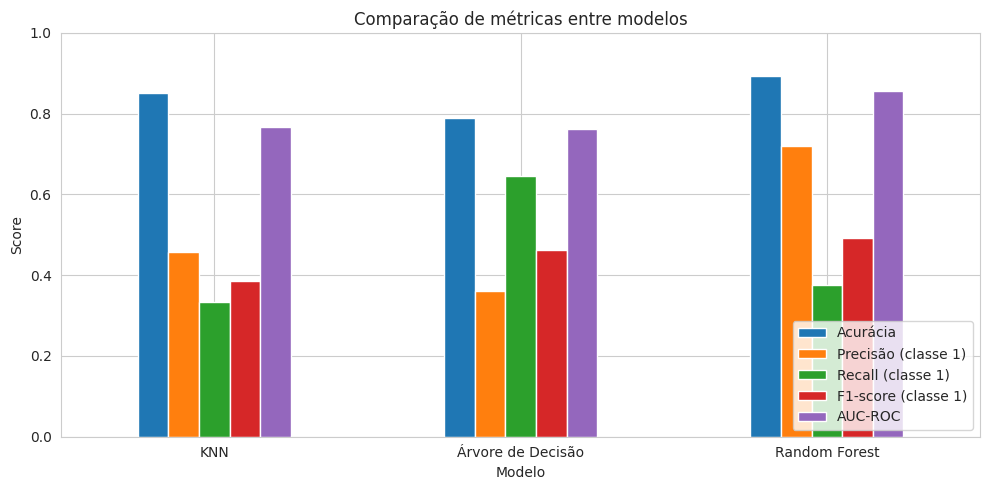

In [4]:
resultados_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Comparação de métricas entre modelos")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 3.1 Relatórios de classificação e matrizes de confusão

=== KNN ===
              precision    recall  f1-score   support

 Baixa/Média       0.90      0.94      0.92       295
        Alta       0.46      0.33      0.39        48

    accuracy                           0.85       343
   macro avg       0.68      0.63      0.65       343
weighted avg       0.83      0.85      0.84       343

=== Árvore de Decisão ===
              precision    recall  f1-score   support

 Baixa/Média       0.93      0.81      0.87       295
        Alta       0.36      0.65      0.46        48

    accuracy                           0.79       343
   macro avg       0.65      0.73      0.67       343
weighted avg       0.85      0.79      0.81       343

=== Random Forest ===
              precision    recall  f1-score   support

 Baixa/Média       0.91      0.98      0.94       295
        Alta       0.72      0.38      0.49        48

    accuracy                           0.89       343
   macro avg       0.81      0.68      0.72       343
weighted avg  

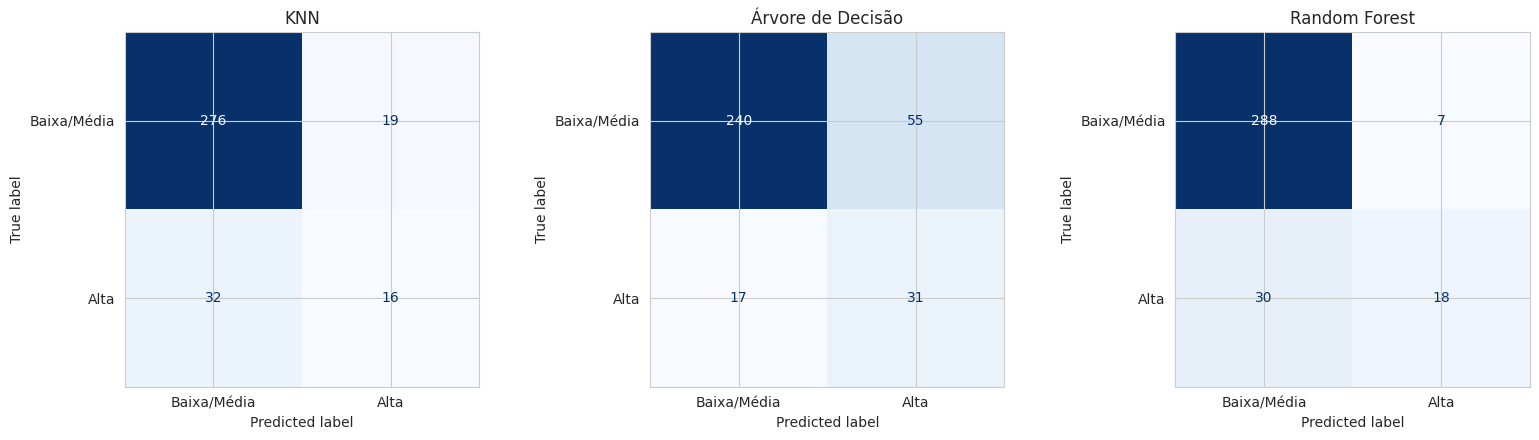

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (nome, modelo) in zip(axes, modelos.items()):
    y_pred = modelo.predict(X_test)
    print(f"=== {nome} ===")
    print(classification_report(y_test, y_pred, target_names=["Baixa/Média", "Alta"]))

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Baixa/Média", "Alta"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nome)

plt.tight_layout()
plt.show()

### 3.2 Curva ROC e AUC

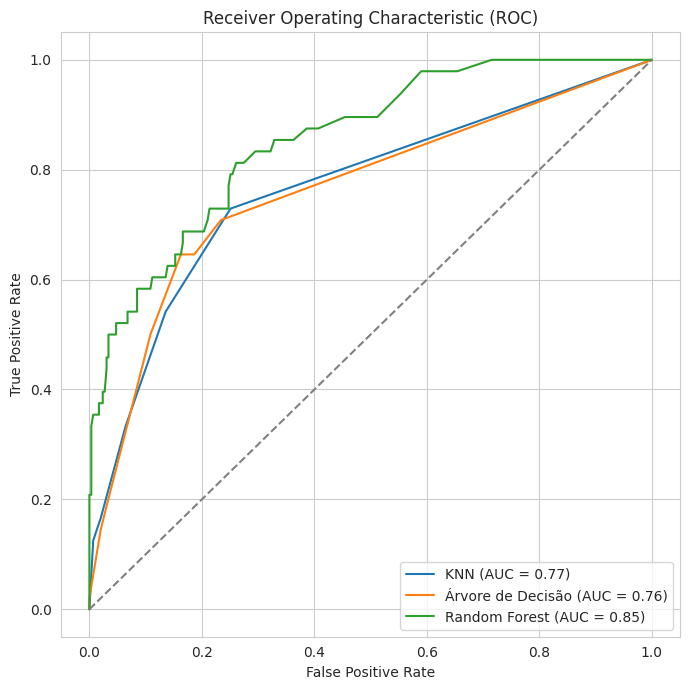

In [6]:
plt.figure(figsize=(7, 7))

for nome, modelo in modelos.items():
    y_prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("Receiver Operating Characteristic (ROC)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Modelo escolhido e justificativa das métricas:** priorizamos AUC-ROC e a
precisão/recall da classe "Alta Qualidade" em vez da acurácia isolada, porque
o problema é desbalanceado (notebook 01) e o custo de negócio de errar um
vinho realmente bom é maior do que apenas "acertar a média". Com esse
critério, o **Random Forest** é o modelo recomendado: melhor acurácia, melhor
AUC e melhor precisão para a classe de interesse — mesmo tendo recall menor
que a Árvore de Decisão isolada (discutido abaixo).

## 4. Importância das variáveis (Random Forest)

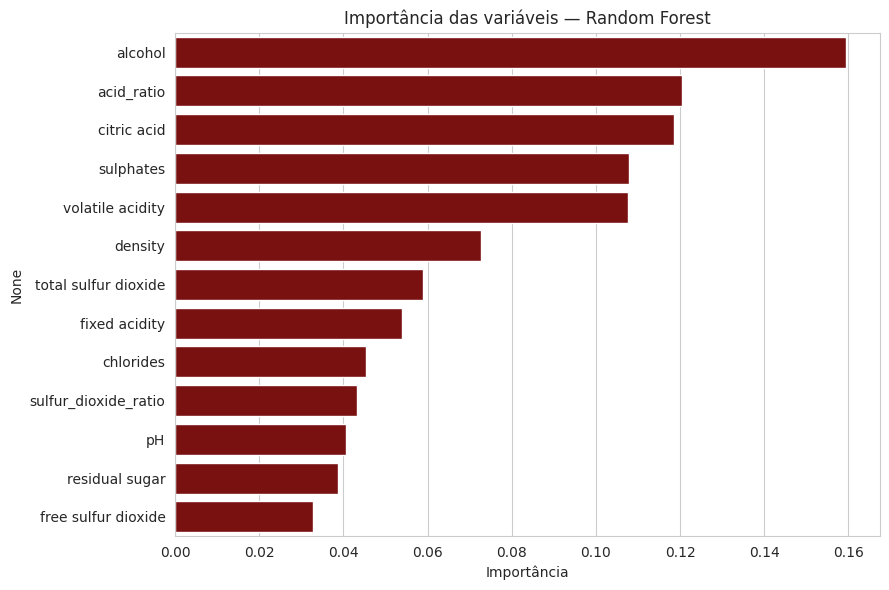

alcohol                 0.159520
acid_ratio              0.120462
citric acid             0.118465
sulphates               0.107886
volatile acidity        0.107509
density                 0.072730
total sulfur dioxide    0.058790
fixed acidity           0.053992
chlorides               0.045442
sulfur_dioxide_ratio    0.043114
pH                      0.040651
residual sugar          0.038626
free sulfur dioxide     0.032813
dtype: float64

In [7]:
rf_clf = modelos["Random Forest"]
importancias = pd.Series(rf_clf.feature_importances_, index=X_test.columns)
importancias = importancias.sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=importancias.values, y=importancias.index, color="darkred")
plt.title("Importância das variáveis — Random Forest")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

importancias

## 5. Interpretação e implicações práticas

- No Random Forest, as variáveis mais importantes para prever a qualidade
  foram, nesta ordem: **`alcohol`**, **`acid_ratio`** (feature criada no
  notebook 02), **`citric acid`**, **`sulphates`** e **`volatile acidity`** —
  resultado consistente com a matriz de correlação do notebook 01, onde
  `alcohol` e `volatile acidity` já eram as variáveis mais fortemente
  associadas à qualidade. A boa colocação de `acid_ratio` valida a decisão de
  criar essa feature.
- **Implicação para a produção:** como `alcohol` e a relação entre acidez
  fixa/volátil são os fatores mais determinantes, o controle do processo de
  fermentação — que afeta diretamente o teor alcoólico e a formação de ácido
  acético (componente central da acidez volátil) — é o ponto de maior
  alavancagem para elevar a qualidade percebida do produto, mais do que, por
  exemplo, ajustes finos em pH ou densidade.
- **Comparação entre os modelos:** o Random Forest teve o melhor desempenho
  geral (acurácia 0.89, AUC 0.86, melhor precisão para a classe "Alta
  Qualidade"), mas identificou menos da metade dos vinhos de alta qualidade
  de fato existentes (recall 0.38). A Árvore de Decisão isolada teve o maior
  recall (0.65), às custas de mais falsos positivos. A escolha entre os dois
  depende do custo de negócio: se o objetivo é não deixar passar nenhum vinho
  potencialmente bom (mesmo com falsos alarmes), a Árvore de Decisão é
  preferível; se o objetivo é confiar nas previsões positivas do modelo, o
  Random Forest é mais indicado.

## 6. Limitações e próximos passos

- Base relativamente pequena (1.143 amostras) e desbalanceada (~14% de vinhos
  de alta qualidade), o que limita a capacidade de qualquer modelo aprender
  bem os padrões da classe minoritária — refletido no recall moderado de
  todos os modelos testados.
- O dataset contém apenas variáveis físico-químicas — fatores sensoriais,
  safra, tipo de uva e processo de vinificação não estão representados, o que
  impõe um teto natural à performance de qualquer modelo treinado só com esses
  dados.
- Próximos passos sugeridos: técnicas de balanceamento de classes (ex.
  SMOTE), otimização de hiperparâmetros (`GridSearchCV`/`RandomizedSearchCV`)
  e testar outros algoritmos (ex. Gradient Boosting) para tentar melhorar o
  recall da classe minoritária sem sacrificar a precisão.